In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
img = cv2.imread("C:/Users/Admin/UniBE/data/images/479_30_mouse_R_01-06-2025_14-43-14_3.tif", cv2.IMREAD_UNCHANGED)

In [8]:
new_image = np.zeros(img.shape, img.dtype)

alpha = 8 # Simple contrast control
beta = 25  # Simple brightness control
 
# # Initialize values
# print(' Basic Linear Transforms ')
# print('-------------------------')
# try:
#     alpha = float(input('* Enter the alpha value [1.0-3.0]: '))
#     beta = int(input('* Enter the beta value [0-100]: '))
# except ValueError:
#     print('Error, not a number')
 
 
new_image = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)
new_image = cv2.medianBlur(new_image, 5)

cv2.imshow('Original Image', img)
cv2.imshow('New Image', new_image)
cv2.imwrite('edited.png', new_image)
cv2.waitKey()
cv2.destroyAllWindows()

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Apply CLAHE (Adaptive Histogram Equalization)
clahe = cv2.createCLAHE(clipLimit=4, tileGridSize=(4,4))
cl1 = clahe.apply(gray)
cv2.imshow("img", gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
brightness = 30
contrast = 10
img = np.int16(img)
img = img * (contrast/127+1) - contrast + brightness
img = np.clip(img, 0, 255)
img = np.uint8(img)
img = cv2.medianBlur(img, 5)
cv2.imshow("img", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

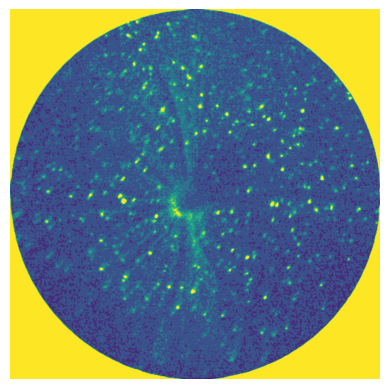

In [2]:
im = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\images\\no_bg\\479_30_mouse_R_05-06-2025_14-14-29_4_edited.png", cv2.IMREAD_UNCHANGED)[:,:,2].copy()
im = cv2.medianBlur(im, ksize=3)
plt.imshow(im)
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

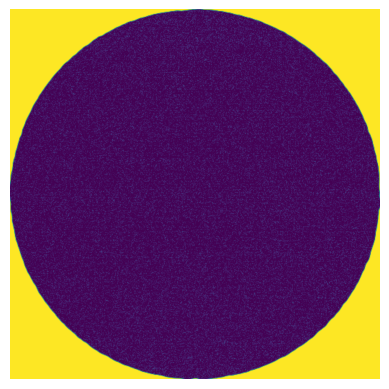

In [3]:
bg = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\images\\no_bg\\479_30_mouse_R_05-06-2025_14-14-39_6_edited.png", cv2.IMREAD_UNCHANGED)[:,:,0].copy()
g = cv2.medianBlur(bg, ksize=101)
plt.imshow(bg)
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

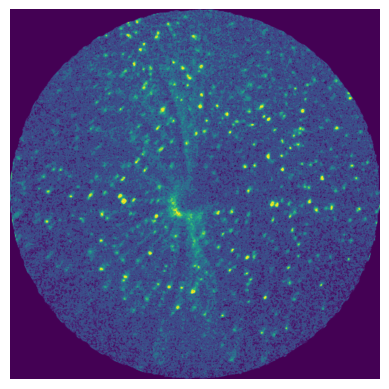

In [4]:
signal = cv2.subtract(im, bg)
#imshow(signal)
signal = (signal / signal.max() * 255).astype(np.uint8)
plt.imshow(signal)
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

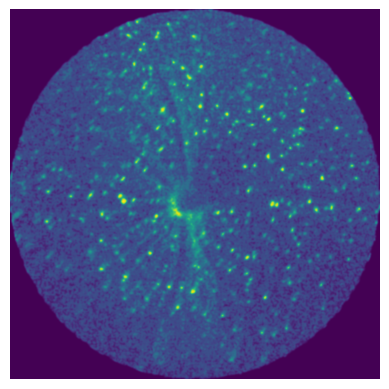

In [5]:
smooth = cv2.GaussianBlur(signal, ksize=None, sigmaX=2)
plt.imshow(smooth)
plt.axis('off')

In [6]:
print(smooth.min(), smooth.max(), smooth.mean())

0 251 50.30004798334775


(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

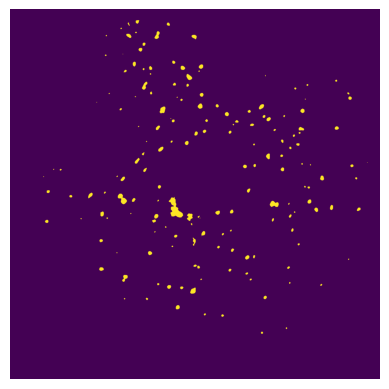

In [7]:
valmask = (smooth > 150)
plt.imshow(valmask)
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

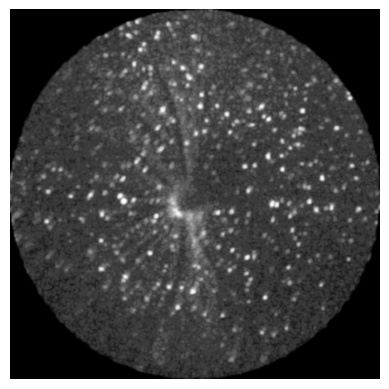

In [8]:
dilated = cv2.dilate(smooth, np.ones((3,3), np.uint8))
plt.imshow(dilated, cmap='gray')
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

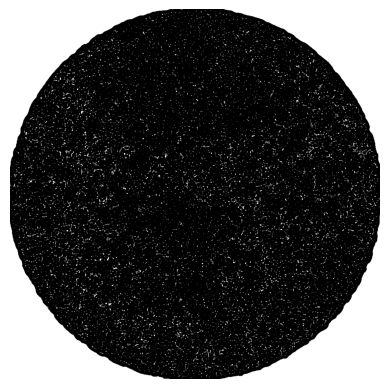

In [9]:
peakmask = (smooth == dilated)
plt.imshow(peakmask, cmap='gray')
plt.axis('off')

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

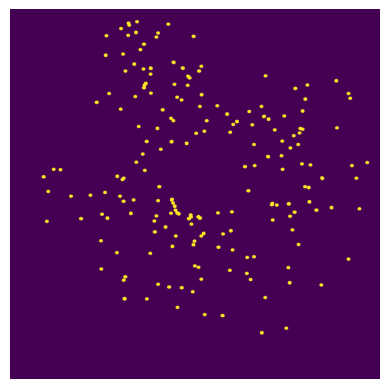

In [10]:
blobs = (valmask & peakmask)
# merge peaks that should be in the same blob
#blobs = cv.dilate(blobs.astype('u1'), kernel=None, iterations=10)
blobs = cv2.morphologyEx(blobs * np.uint8(255), cv2.MORPH_DILATE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11,11)))
blobs = blobs.astype(bool)
plt.imshow(blobs)
plt.axis('off')

In [11]:
(nlabels, labelmap, stats, centroids) = cv2.connectedComponentsWithStats(blobs.astype(np.uint8))
print(nlabels-1, "components")
#centroids

170 components


In [12]:
np.hstack([centroids[:5], stats[:5,2:4]]) # first is background

array([[ 543.15294344,  544.60258577, 1088.        , 1088.        ],
       [ 373.        ,   37.        ,   11.        ,   11.        ],
       [ 349.07006369,   43.99363057,   13.        ,   17.        ],
       [ 465.        ,   44.        ,   11.        ,   11.        ],
       [ 326.        ,   57.        ,   11.        ,   11.        ]])

(np.float64(-0.5), np.float64(1087.5), np.float64(1087.5), np.float64(-0.5))

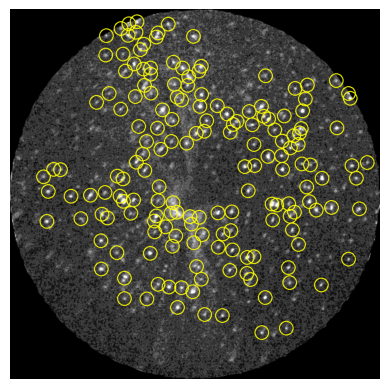

In [13]:
canvas = cv2.cvtColor(signal, cv2.COLOR_BGR2RGB)
for pt in centroids[1:]:
    cv2.circle(canvas, center=pt.astype(int), radius=20, color=(255,255,0), thickness=2)
plt.imshow(canvas)
plt.axis('off')

In [14]:
centroids

array([[ 543.15294344,  544.60258577],
       [ 373.        ,   37.        ],
       [ 349.07006369,   43.99363057],
       [ 465.        ,   44.        ],
       [ 326.        ,   57.        ],
       [ 370.        ,   68.5       ],
       [ 435.        ,   70.        ],
       [ 283.        ,   78.        ],
       [ 347.        ,   77.        ],
       [ 539.5       ,   80.        ],
       [ 430.        ,   82.        ],
       [ 393.5       ,  103.        ],
       [ 383.        ,  119.        ],
       [ 332.        ,  132.        ],
       [ 281.        ,  135.5       ],
       [ 480.62962963,  156.35185185],
       [ 365.        ,  161.5       ],
       [ 562.        ,  168.        ],
       [ 413.37037037,  173.64814815],
       [ 507.62962963,  173.35185185],
       [ 392.        ,  176.        ],
       [ 339.        ,  182.        ],
       [ 555.5       ,  182.        ],
       [ 413.        ,  191.        ],
       [ 751.        ,  196.        ],
       [ 525.42073171,  1

In [15]:
# KNN
from sklearn.neighbors import NearestNeighbors

neigh = NearestNeighbors(n_neighbors=5+1)
neigh.fit(centroids[1:])
distances, indices = neigh.kneighbors(centroids[1:])

In [16]:
import networkx as nx
G = nx.Graph()

# Add nodes
for i, point in enumerate(centroids[1:]):
    G.add_node(i, pos=point)

# Add edges
for i, neighbors in enumerate(indices):
    for neighbor in neighbors[1:]:
        G.add_edge(i, neighbor)


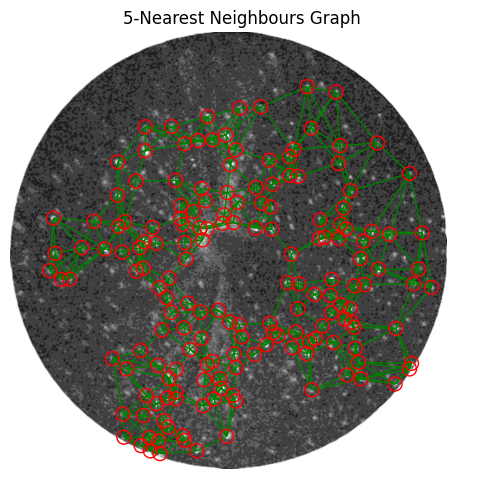

In [25]:
pos = nx.get_node_attributes(G, 'pos')

plt.figure(figsize=(6,6))
img_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

nx.draw(G, pos, node_size=100, node_color='none', edgecolors='red', edge_color='green', linewidths=1)
plt.title(f"{5}-Nearest Neighbours Graph")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Reduce the radius of interest
# lesser points
# point by point comparison

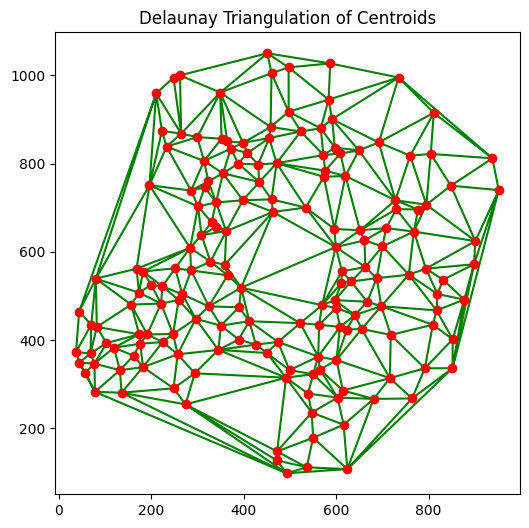

In [18]:
# Delaunay Triangulation
from scipy.spatial import Delaunay

tri = Delaunay(centroids[1:])

# Plotting
plt.figure(figsize=(6,6))
plt.triplot(centroids[1:,1], centroids[1:,0], tri.simplices, color='green')  # plot triangles
plt.plot(centroids[1:,1], centroids[1:,0], 'ro')  # plot points
plt.title("Delaunay Triangulation of Centroids")
plt.show()